# DAVIS GCN + CNN Drug–Target Affinity Prediction

This notebook evaluates a **GCN + CNN** model on the DAVIS drug–target affinity dataset.

The drug is represented as a molecular graph and encoded using a Graph Convolutional Network (GCN).  
The protein is represented as an amino-acid sequence and encoded using a one-dimensional CNN.

Three evaluation settings are used:

- Random split
- Cold-drug split
- Cold-target split

The same model architecture and training settings are used for all three experiments so that the effect of the data split can be compared fairly.

## Notebook workflow

```text
Raw DAVIS dataset
        │
        ▼
Load drugs, proteins and affinity matrix
        │
        ▼
Convert DAVIS Kd values to pKd
        │
        ├───────────────────────────────┐
        ▼                               ▼
SMILES                              Protein sequence
        │                               │
        ▼                               ▼
RDKit molecular graph              Integer encoding
        │                               │
        ▼                               ▼
GCN drug encoder                   1D CNN protein encoder
        └───────────────┬───────────────┘
                        ▼
                Combined representation
                        │
                        ▼
                 Affinity prediction
                        │
        ┌───────────────┼────────────────┐
        ▼               ▼                ▼
   Random split     Cold-drug        Cold-target
        │               │                │
        ▼               ▼                ▼
 Train / validate / test with early stopping
        │               │                │
        └───────────────┼────────────────┘
                        ▼
            MSE, RMSE, MAE, CI, Pearson
                        │
                        ▼
         Save checkpoints, predictions,
              figures and metrics
                        │
                        ▼
             Compare the three splits
```

The notebook starts from the raw DAVIS files and finishes by saving a single model-level metrics table for later comparison with GAT and GIN.

In [2]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False,
)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = (
    "https://github.com/"
    "Thebluesky303/"
    "msc-dissertation-drug-repurposing.git"
)

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path(
    "/content/final-msc-dissertation-drug-repurposing"
)

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/"
    "final-msc-dissertation-drug-repurposing"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT / "results"
)


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in result_folders:
    (
        DRIVE_RESULTS / folder_name
    ).mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get(
    "colab-dissertation"
)

if not token:
    raise ValueError(
        "GITHUB_TOKEN was not found in Colab Secrets."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_auth = (
    f"AUTHORIZATION: basic {auth}"
)


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (
    REPO_DIR / ".git"
).exists():

    print(
        "Cloning repository..."
    )

    subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader={git_auth}",
            "clone",
            "--branch",
            BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    print(
        "Repository already exists."
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "fetch",
            "origin",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "switch",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "pull",
            "--ff-only",
            "origin",
            BRANCH,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = (
    REPO_DIR / "results"
)

if LOCAL_RESULTS.is_symlink():

    current_target = (
        LOCAL_RESULTS.resolve()
    )

    if current_target != (
        DRIVE_RESULTS.resolve()
    ):
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():

    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():

        destination = (
            DRIVE_RESULTS
            / item.name
        )

        if item.is_dir():

            shutil.copytree(
                item,
                destination,
                dirs_exist_ok=True,
            )

        else:

            shutil.copy2(
                item,
                destination,
            )

    shutil.rmtree(
        LOCAL_RESULTS
    )


if not LOCAL_RESULTS.exists():

    os.symlink(
        DRIVE_RESULTS,
        LOCAL_RESULTS,
        target_is_directory=True,
    )


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(
    REPO_DIR
)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(
    [
        "git",
        "branch",
        "--show-current",
    ],
    text=True,
).strip()

commit = subprocess.check_output(
    [
        "git",
        "log",
        "-1",
        "--oneline",
    ],
    text=True,
).strip()


print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print(
    "Repository:",
    REPO_DIR,
)

print(
    "Branch:",
    branch,
)

print(
    "Commit:",
    commit,
)

print(
    "Results saved to Drive:",
    LOCAL_RESULTS.resolve(),
)

print(
    "CUDA available:",
    torch.cuda.is_available(),
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository already exists.

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 6427473 Increase maximum training epochs to 200
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
/content
Project requirements installed.
PyTorch: 2.11.0+cu128
PyG: 2.8.0.post1
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
Environment ready.


# Part A — Setup and data preparation

## 1. Imports

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw
from torch_geometric.loader import DataLoader

## 2. Locate the project folder

The notebook expects the project to contain `config.py`, `src/`, `data/`, and `results/`.
The code below works when the notebook is run from the project folder, from the `notebooks/` folder, or from a typical Google Colab clone.

In [4]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")
    if content_dir.exists():
        candidates.extend(path.parent for path in content_dir.glob("*/config.py"))
        candidates.extend(path.parent for path in content_dir.glob("*/final_aml_gnn_dta/config.py"))

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Open the notebook from final_aml_gnn_dta or clone/copy the project into the current environment."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project settings and shared functions

In [5]:
from config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    DAVIS_DIR,
    FIGURES_DIR,
    LEARNING_RATE,
    MAX_EPOCHS,
    METRICS_DIR,
    PREDICTIONS_DIR,
    RANDOM_SEED,
    TRAIN_RATIO,
    VALIDATION_RATIO,
    TEST_RATIO,
)

from src.models import GCNCNN, count_trainable_parameters
from src.preprocessing import (
    ATOM_FEATURE_DIM,
    BOND_FEATURE_DIM,
    InteractionDataset,
    build_drug_graph_cache,
    build_protein_tensor_cache,
    check_cold_split,
    cold_drug_split,
    cold_target_split,
    load_deepdta_dataset,
    random_split,
)
from src.training import evaluate_model, fit_model
from src.utils import (
    get_device,
    save_predictions_csv,
    set_seed,
)

set_seed(RANDOM_SEED)
device = get_device()

print("Device:", device)
print("Random seed:", RANDOM_SEED)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Random seed: 42
Batch size: 64
Maximum epochs: 200
Learning rate: 0.001


## 4. Load the DAVIS dataset

The standard DAVIS files are expected in:

```text
data/raw/davis/
├── ligands_can.txt
├── proteins.txt
└── Y
```

For DAVIS, the original dissociation constants are converted from **Kd (nM)** to **pKd**, where larger values indicate stronger binding.

In [6]:
davis_df = load_deepdta_dataset(
    dataset_dir=DAVIS_DIR,
    dataset_name="davis",
    transform_davis=True,
)

print("Number of interactions:", len(davis_df))
print("Unique drugs:", davis_df["drug_id"].nunique())
print("Unique targets:", davis_df["target_id"].nunique())
print(
    "pKd range:",
    f'{davis_df["affinity"].min():.3f}',
    "to",
    f'{davis_df["affinity"].max():.3f}',
)

display(davis_df.head())

Number of interactions: 30056
Unique drugs: 68
Unique targets: 442
pKd range: 5.000 to 10.796


,drug_id,target_id,smiles,protein_sequence,affinity
0,11314340,AAK1,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,MKKFFDSRREQGGSGLGSGSSGGGGSTSGLGSGYIGRVFGIGRQQV...,7.366532
1,11314340,ABL1(E255K),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
2,11314340,ABL1(F317I),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
3,11314340,ABL1(F317I)p,CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000
4,11314340,ABL1(F317L),CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...,PFWKILNPLLERGTYYYFMGQQPGKVLGDQRRPSLPALHFIKGAGK...,5.000000


## 5. Inspect the dataset

In [7]:
dataset_summary = pd.DataFrame(
    {
        "measure": [
            "Interactions",
            "Unique drugs",
            "Unique targets",
            "Minimum pKd",
            "Mean pKd",
            "Maximum pKd",
        ],
        "value": [
            len(davis_df),
            davis_df["drug_id"].nunique(),
            davis_df["target_id"].nunique(),
            davis_df["affinity"].min(),
            davis_df["affinity"].mean(),
            davis_df["affinity"].max(),
        ],
    }
)

display(dataset_summary)

,measure,value
0,Interactions,30056.000000
1,Unique drugs,68.000000
2,Unique targets,442.000000
3,Minimum pKd,5.000000
4,Mean pKd,5.451535
5,Maximum pKd,10.795880


## 6. Prepare drug molecular graphs and protein sequences

Each unique drug is converted once into an RDKit/PyTorch Geometric molecular graph and cached.

Each unique protein sequence is also encoded once and cached. Reusing these representations avoids repeating the same preprocessing for every interaction pair.

In [8]:
drug_graph_cache = build_drug_graph_cache(davis_df)
protein_tensor_cache = build_protein_tensor_cache(davis_df)

print("Cached drug graphs:", len(drug_graph_cache))
print("Cached protein sequences:", len(protein_tensor_cache))
print("Atom feature dimension:", ATOM_FEATURE_DIM)
print("Bond feature dimension:", BOND_FEATURE_DIM)

Cached drug graphs: 68
Cached protein sequences: 442
Atom feature dimension: 9
Bond feature dimension: 6


## 7. Inspect one molecular graph

Drug ID: 11314340
SMILES: CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC=C4)N
Number of atoms: 27
Directed graph edges: 60
Node feature shape: (27, 9)
Bond feature shape: (60, 6)


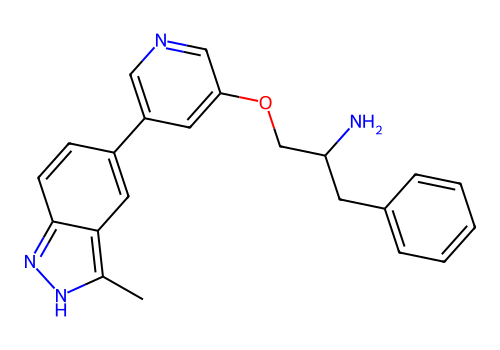

In [9]:
example_row = davis_df.iloc[0]
example_drug_id = str(example_row["drug_id"])
example_smiles = example_row["smiles"]
example_graph = drug_graph_cache[example_drug_id]

print("Drug ID:", example_drug_id)
print("SMILES:", example_smiles)
print("Number of atoms:", example_graph.num_nodes)
print("Directed graph edges:", example_graph.edge_index.shape[1])
print("Node feature shape:", tuple(example_graph.x.shape))
print("Bond feature shape:", tuple(example_graph.edge_attr.shape))

molecule = Chem.MolFromSmiles(example_smiles)
display(Draw.MolToImage(molecule, size=(500, 350)))

## 8. Helper functions used by the three experiments

The functions below only organise repeated notebook steps.  
Each split still creates a **fresh GCN + CNN model** and is trained independently.

In [10]:
def create_loaders(train_df, validation_df, test_df):
    train_dataset = InteractionDataset(
        train_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    validation_dataset = InteractionDataset(
        validation_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    test_dataset = InteractionDataset(
        test_df,
        drug_graph_cache,
        protein_tensor_cache,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, validation_loader, test_loader


def print_split_summary(train_df, validation_df, test_df):
    summary = pd.DataFrame(
        {
            "partition": ["Train", "Validation", "Test"],
            "interactions": [
                len(train_df),
                len(validation_df),
                len(test_df),
            ],
            "unique_drugs": [
                train_df["drug_id"].nunique(),
                validation_df["drug_id"].nunique(),
                test_df["drug_id"].nunique(),
            ],
            "unique_targets": [
                train_df["target_id"].nunique(),
                validation_df["target_id"].nunique(),
                test_df["target_id"].nunique(),
            ],
        }
    )

    display(summary)


def plot_training_history(history, split_name):
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training MSE",
    )
    plt.plot(
        history_df["epoch"],
        history_df["validation_loss"],
        label="Validation MSE",
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.title(f"DAVIS GCN + CNN — {split_name}")
    plt.legend()
    plt.tight_layout()

    figure_path = (
        FIGURES_DIR
        / f"davis_gcn_cnn_{split_name}_training.png"
    )
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()

    return history_df


def run_gcn_experiment(
    split_name,
    train_df,
    validation_df,
    test_df,
):
    print(f"Running split: {split_name}")
    print("-" * 60)

    train_loader, validation_loader, test_loader = create_loaders(
        train_df,
        validation_df,
        test_df,
    )

    model = GCNCNN()
    trainable_parameters = count_trainable_parameters(model)

    print("Trainable parameters:", f"{trainable_parameters:,}")

    checkpoint_path = (
        CHECKPOINTS_DIR
        / f"davis_gcn_cnn_{split_name}.pt"
    )

    training_result = fit_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        checkpoint_path=checkpoint_path,
        max_epochs=MAX_EPOCHS,
        learning_rate=LEARNING_RATE,
    )

    history_df = plot_training_history(
        training_result["history"],
        split_name,
    )

    test_result = evaluate_model(
        model=model,
        data_loader=test_loader,
        device=device,
    )

    metrics = test_result["metrics"]

    predictions_df = test_df.copy()
    predictions_df["true_affinity"] = test_result["y_true"]
    predictions_df["predicted_affinity"] = test_result["y_pred"]
    predictions_df["prediction_error"] = (
        predictions_df["predicted_affinity"]
        - predictions_df["true_affinity"]
    )

    prediction_path = (
        PREDICTIONS_DIR
        / f"davis_gcn_cnn_{split_name}.csv"
    )

    save_predictions_csv(
        predictions_df,
        prediction_path,
    )

    result_row = {
        "dataset": "DAVIS",
        "model": "GCN + CNN",
        "split": split_name,
        "best_epoch": training_result["best_epoch"],
        "completed_epochs": training_result["completed_epochs"],
        "best_validation_mse": training_result[
            "best_validation_mse"
        ],
        "test_mse": metrics["mse"],
        "test_rmse": metrics["rmse"],
        "test_mae": metrics["mae"],
        "ci": metrics["ci"],
        "pearson": metrics["pearson"],
        "trainable_parameters": trainable_parameters,
    }

    print()
    print("Best epoch:", result_row["best_epoch"])
    print(
        "Best validation MSE:",
        f'{result_row["best_validation_mse"]:.4f}',
    )
    print("Test MSE:", f'{result_row["test_mse"]:.4f}')
    print("Test RMSE:", f'{result_row["test_rmse"]:.4f}')
    print("Test MAE:", f'{result_row["test_mae"]:.4f}')
    print("Concordance index:", f'{result_row["ci"]:.4f}')
    print("Pearson correlation:", f'{result_row["pearson"]:.4f}')

    return {
        "model": model,
        "result": result_row,
        "history": history_df,
        "predictions": predictions_df,
        "checkpoint_path": checkpoint_path,
        "prediction_path": prediction_path,
    }

# Part B — Random split experiment

In the random split, interaction pairs are divided randomly into training, validation, and test sets.  
A drug or protein may therefore appear in more than one partition.

This setting measures performance when the model is evaluated on unseen **interaction pairs**, but not necessarily unseen drugs or proteins.

## 9. Create the random split

In [11]:
random_train_df, random_validation_df, random_test_df = random_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    random_train_df,
    random_validation_df,
    random_test_df,
)

random_drug_overlap = (
    set(random_train_df["drug_id"])
    & set(random_test_df["drug_id"])
)

random_target_overlap = (
    set(random_train_df["target_id"])
    & set(random_test_df["target_id"])
)

print(
    "Train-test drug overlap:",
    len(random_drug_overlap),
)
print(
    "Train-test target overlap:",
    len(random_target_overlap),
)

,partition,interactions,unique_drugs,unique_targets
0,Train,24044,68,442
1,Validation,3005,68,442
2,Test,3007,68,442


Train-test drug overlap: 68
Train-test target overlap: 442


## 10. Train and evaluate GCN + CNN on the random split

Running split: random
------------------------------------------------------------
Trainable parameters: 384,129
Epoch 001 | Train MSE: 1.4052 | Validation MSE: 1.1591
Epoch 002 | Train MSE: 1.0384 | Validation MSE: 1.0461
Epoch 003 | Train MSE: 1.0100 | Validation MSE: 0.7969
Epoch 004 | Train MSE: 0.9795 | Validation MSE: 1.0739
Epoch 005 | Train MSE: 0.9490 | Validation MSE: 0.6456
Epoch 006 | Train MSE: 0.9118 | Validation MSE: 0.6368
Epoch 007 | Train MSE: 0.8959 | Validation MSE: 0.5758
Epoch 008 | Train MSE: 0.8873 | Validation MSE: 0.6261
Epoch 009 | Train MSE: 0.8673 | Validation MSE: 0.5922
Epoch 010 | Train MSE: 0.8555 | Validation MSE: 0.6149
Epoch 011 | Train MSE: 0.8228 | Validation MSE: 0.6080
Epoch 012 | Train MSE: 0.7987 | Validation MSE: 0.5950
Epoch 013 | Train MSE: 0.7890 | Validation MSE: 0.5675
Epoch 014 | Train MSE: 0.7611 | Validation MSE: 0.5778
Epoch 015 | Train MSE: 0.7423 | Validation MSE: 0.5845
Epoch 016 | Train MSE: 0.7310 | Validation MSE: 0.5800
Epoch 0

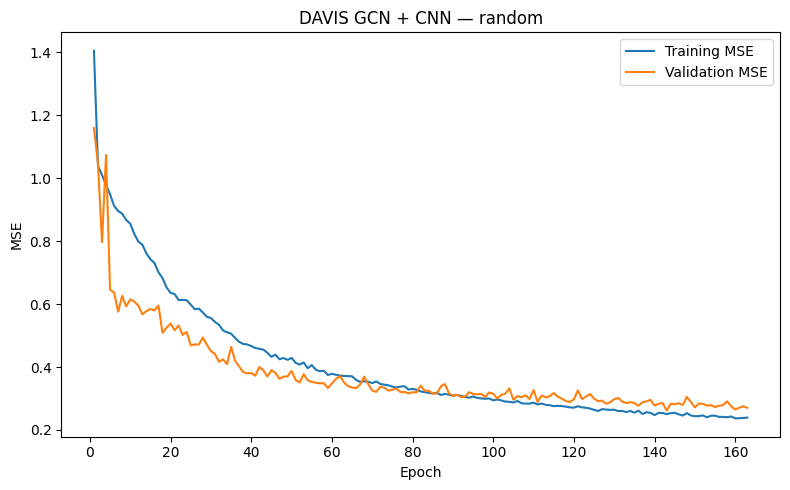


Best epoch: 143
Best validation MSE: 0.2619
Test MSE: 0.2607
Test RMSE: 0.5105
Test MAE: 0.2993
Concordance index: 0.8770
Pearson correlation: 0.8115


In [12]:
random_result = run_gcn_experiment(
    split_name="random",
    train_df=random_train_df,
    validation_df=random_validation_df,
    test_df=random_test_df,
)

## 11. Inspect random-split predictions

In [13]:
display(
    random_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,24779724,ROCK2,5.000000,5.036516,0.036516
1,11984591,PRKG1,5.000000,5.788593,0.788593
2,156414,PFCDPK1(Pfalciparum),5.000000,5.092639,0.092639
3,42642645,TSSK1B,5.000000,5.658351,0.658351
4,126565,EPHA2,6.102373,5.437917,-0.664456
5,11626560,CLK3,5.000000,5.431130,0.431130
6,9926791,HIPK1,5.000000,5.561931,0.561931
7,156414,TTK,5.000000,5.072711,0.072711
8,11234052,PIK3CA(Q546K),5.000000,5.033880,0.033880
9,17755052,TAOK1,5.000000,5.409299,0.409299


# Part C — Cold-drug experiment

In the cold-drug split, drugs are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen drugs**, while protein targets may have been observed during training. This provides a more demanding assessment of generalisation to new compounds.

## 12. Create and verify the cold-drug split

In [14]:
cold_drug_train_df, cold_drug_validation_df, cold_drug_test_df = cold_drug_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
)

cold_drug_is_valid = check_cold_split(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
    column="drug_id",
)

print("No drug overlap:", cold_drug_is_valid)

assert cold_drug_is_valid, "Cold-drug split contains overlapping drugs."

,partition,interactions,unique_drugs,unique_targets
0,Train,23868,54,442
1,Validation,2652,6,442
2,Test,3536,8,442


No drug overlap: True


## 13. Train and evaluate GCN + CNN on the cold-drug split

Running split: cold_drug
------------------------------------------------------------
Trainable parameters: 384,129
Epoch 001 | Train MSE: 1.3896 | Validation MSE: 1.0971
Epoch 002 | Train MSE: 1.0934 | Validation MSE: 0.8006
Epoch 003 | Train MSE: 1.0137 | Validation MSE: 1.6464
Epoch 004 | Train MSE: 0.9870 | Validation MSE: 0.9948
Epoch 005 | Train MSE: 0.9649 | Validation MSE: 0.6782
Epoch 006 | Train MSE: 0.9313 | Validation MSE: 0.9468
Epoch 007 | Train MSE: 0.9191 | Validation MSE: 0.7055
Epoch 008 | Train MSE: 0.9007 | Validation MSE: 0.8442
Epoch 009 | Train MSE: 0.8984 | Validation MSE: 0.7561
Epoch 010 | Train MSE: 0.8667 | Validation MSE: 0.9712
Epoch 011 | Train MSE: 0.8463 | Validation MSE: 1.1234
Epoch 012 | Train MSE: 0.8269 | Validation MSE: 0.6831
Epoch 013 | Train MSE: 0.8343 | Validation MSE: 1.2248
Epoch 014 | Train MSE: 0.8004 | Validation MSE: 1.0097
Epoch 015 | Train MSE: 0.7886 | Validation MSE: 0.6737
Epoch 016 | Train MSE: 0.7680 | Validation MSE: 0.8158
Epoc

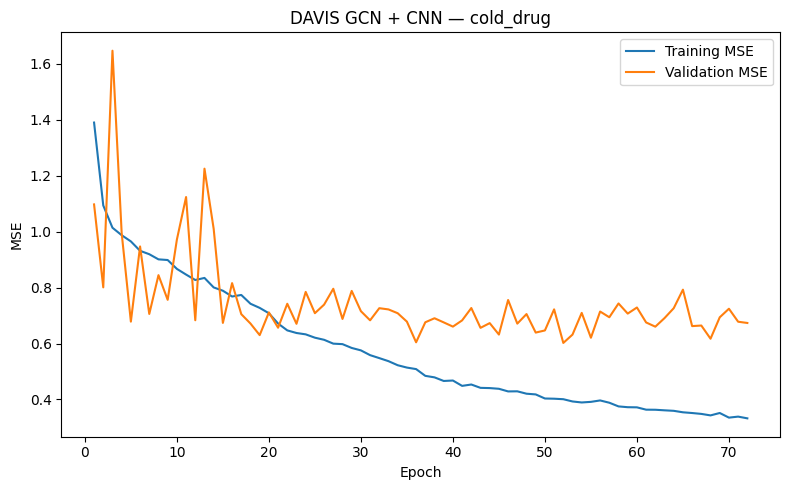


Best epoch: 52
Best validation MSE: 0.6020
Test MSE: 0.6398
Test RMSE: 0.7999
Test MAE: 0.4854
Concordance index: 0.7736
Pearson correlation: 0.5305


In [15]:
cold_drug_result = run_gcn_experiment(
    split_name="cold_drug",
    train_df=cold_drug_train_df,
    validation_df=cold_drug_validation_df,
    test_df=cold_drug_test_df,
)

## 14. Inspect cold-drug predictions

In [16]:
display(
    cold_drug_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,9926054,AAK1,5.0,5.078886,0.078886
1,9926054,ABL1(E255K),5.0,5.144107,0.144107
2,9926054,ABL1(F317I),5.0,5.144107,0.144107
3,9926054,ABL1(F317I)p,5.0,5.144107,0.144107
4,9926054,ABL1(F317L),5.0,5.144107,0.144107
5,9926054,ABL1(F317L)p,5.0,5.144107,0.144107
6,9926054,ABL1(H396P),5.0,5.144107,0.144107
7,9926054,ABL1(H396P)p,5.0,5.144107,0.144107
8,9926054,ABL1(M351T),5.0,5.144107,0.144107
9,9926054,ABL1(Q252H),5.0,5.144107,0.144107


# Part D — Cold-target experiment

In the cold-target split, protein targets are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen protein targets**, while drugs may have been observed during training.

## 15. Create and verify the cold-target split

In [17]:
cold_target_train_df, cold_target_validation_df, cold_target_test_df = cold_target_split(
    davis_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
)

cold_target_is_valid = check_cold_split(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
    column="target_id",
)

print("No target overlap:", cold_target_is_valid)

assert cold_target_is_valid, "Cold-target split contains overlapping targets."

,partition,interactions,unique_drugs,unique_targets
0,Train,24004,68,353
1,Validation,2992,68,44
2,Test,3060,68,45


No target overlap: True


## 16. Train and evaluate GCN + CNN on the cold-target split

Running split: cold_target
------------------------------------------------------------
Trainable parameters: 384,129
Epoch 001 | Train MSE: 1.2835 | Validation MSE: 1.4395
Epoch 002 | Train MSE: 1.0069 | Validation MSE: 0.8693
Epoch 003 | Train MSE: 0.9557 | Validation MSE: 0.7469
Epoch 004 | Train MSE: 0.9288 | Validation MSE: 0.9904
Epoch 005 | Train MSE: 0.9069 | Validation MSE: 0.7777
Epoch 006 | Train MSE: 0.8851 | Validation MSE: 0.7665
Epoch 007 | Train MSE: 0.8526 | Validation MSE: 0.6914
Epoch 008 | Train MSE: 0.8444 | Validation MSE: 0.6663
Epoch 009 | Train MSE: 0.8121 | Validation MSE: 1.0052
Epoch 010 | Train MSE: 0.8122 | Validation MSE: 0.8876
Epoch 011 | Train MSE: 0.7924 | Validation MSE: 0.7012
Epoch 012 | Train MSE: 0.7701 | Validation MSE: 0.6396
Epoch 013 | Train MSE: 0.7601 | Validation MSE: 0.7150
Epoch 014 | Train MSE: 0.7302 | Validation MSE: 0.6106
Epoch 015 | Train MSE: 0.7237 | Validation MSE: 0.6150
Epoch 016 | Train MSE: 0.6996 | Validation MSE: 0.5974
Ep

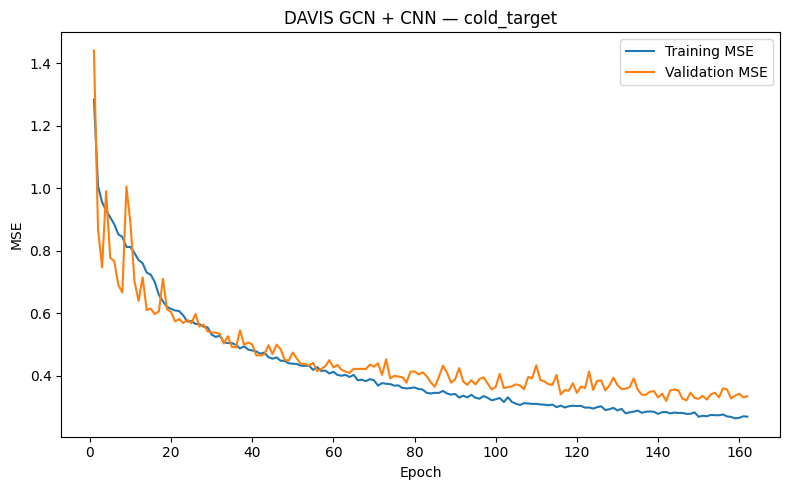


Best epoch: 142
Best validation MSE: 0.3203
Test MSE: 0.4463
Test RMSE: 0.6680
Test MAE: 0.3899
Concordance index: 0.8265
Pearson correlation: 0.7555


In [18]:
cold_target_result = run_gcn_experiment(
    split_name="cold_target",
    train_df=cold_target_train_df,
    validation_df=cold_target_validation_df,
    test_df=cold_target_test_df,
)

## 17. Inspect cold-target predictions

In [19]:
display(
    cold_target_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,11314340,ABL1(H396P),5.000000,5.118960,0.118960
1,11314340,ABL1,5.000000,5.118960,0.118960
2,11314340,ABL1p,5.000000,5.118960,0.118960
3,11314340,ABL2,5.000000,5.122414,0.122414
4,11314340,ADCK3,5.000000,5.130764,0.130764
5,11314340,ADCK4,5.000000,5.165676,0.165676
6,11314340,AURKA,5.000000,5.586571,0.586571
7,11314340,AURKB,5.000000,5.506392,0.506392
8,11314340,AURKC,5.075721,5.730989,0.655268
9,11314340,BMPR1B,5.000000,5.071017,0.071017


# Part E — GCN + CNN results summary

The three experiments are now combined into one table.  
This file is the main output used later by the model-comparison notebook.

## 18. Combine and save the metrics

In [20]:
gcn_results_df = pd.DataFrame(
    [
        random_result["result"],
        cold_drug_result["result"],
        cold_target_result["result"],
    ]
)

metrics_path = METRICS_DIR / "davis_gcn_cnn.csv"
gcn_results_df.to_csv(metrics_path, index=False)

display(gcn_results_df.round(4))

print("Metrics saved to:", metrics_path)

,dataset,model,split,best_epoch,completed_epochs,best_validation_mse,test_mse,test_rmse,test_mae,ci,pearson,trainable_parameters
0,DAVIS,GCN + CNN,random,143,163,0.2619,0.2607,0.5105,0.2993,0.8770,0.8115,384129
1,DAVIS,GCN + CNN,cold_drug,52,72,0.6020,0.6398,0.7999,0.4854,0.7736,0.5305,384129
2,DAVIS,GCN + CNN,cold_target,142,162,0.3203,0.4463,0.6680,0.3899,0.8265,0.7555,384129


Metrics saved to: /content/final-msc-dissertation-drug-repurposing/results/metrics/davis_gcn_cnn.csv


## 19. Compare test RMSE across the three splits

Lower RMSE indicates better affinity prediction.
The cold-start results should be interpreted separately from the random split because they represent more difficult generalisation settings.

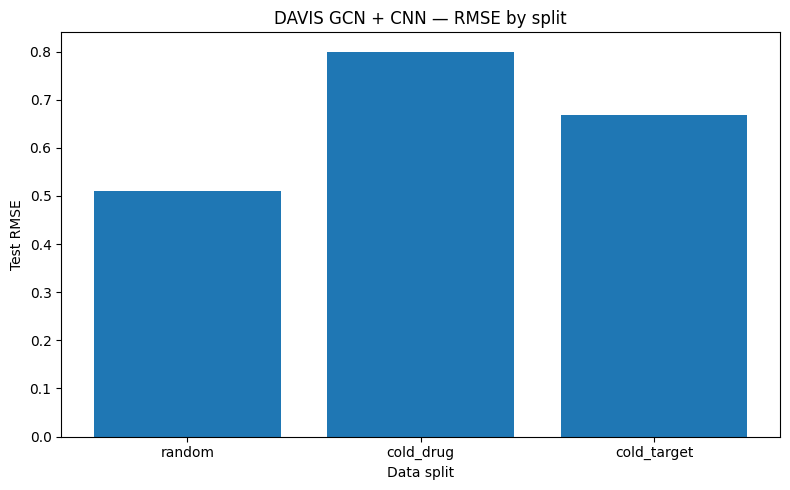

Comparison figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/davis_gcn_cnn_split_comparison.png


In [21]:
plt.figure(figsize=(8, 5))
plt.bar(
    gcn_results_df["split"],
    gcn_results_df["test_rmse"],
)
plt.xlabel("Data split")
plt.ylabel("Test RMSE")
plt.title("DAVIS GCN + CNN — RMSE by split")
plt.tight_layout()

comparison_figure_path = (
    FIGURES_DIR
    / "davis_gcn_cnn_split_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Comparison figure saved to:", comparison_figure_path)

## 20. Final experiment summary

In [22]:
summary_columns = [
    "split",
    "best_epoch",
    "best_validation_mse",
    "test_rmse",
    "test_mae",
    "ci",
    "pearson",
]

final_summary = (
    gcn_results_df[summary_columns]
    .sort_values("test_rmse")
    .reset_index(drop=True)
)

display(final_summary.round(4))

best_split = final_summary.iloc[0]

print(
    "Lowest test RMSE:",
    best_split["split"],
    f'({best_split["test_rmse"]:.4f})',
)

print()
print("Saved outputs")
print("-" * 50)
print("Metrics:", metrics_path)
print("Random predictions:", random_result["prediction_path"])
print("Cold-drug predictions:", cold_drug_result["prediction_path"])
print("Cold-target predictions:", cold_target_result["prediction_path"])
print("Figures folder:", FIGURES_DIR)
print("Checkpoints folder:", CHECKPOINTS_DIR)

,split,best_epoch,best_validation_mse,test_rmse,test_mae,ci,pearson
0,random,143,0.2619,0.5105,0.2993,0.8770,0.8115
1,cold_target,142,0.3203,0.6680,0.3899,0.8265,0.7555
2,cold_drug,52,0.6020,0.7999,0.4854,0.7736,0.5305


Lowest test RMSE: random (0.5105)

Saved outputs
--------------------------------------------------
Metrics: /content/final-msc-dissertation-drug-repurposing/results/metrics/davis_gcn_cnn.csv
Random predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_gcn_cnn_random.csv
Cold-drug predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_gcn_cnn_cold_drug.csv
Cold-target predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/davis_gcn_cnn_cold_target.csv
Figures folder: /content/final-msc-dissertation-drug-repurposing/results/figures
Checkpoints folder: /content/final-msc-dissertation-drug-repurposing/results/checkpoints


### Notebook completion

This notebook has completed the **DAVIS GCN + CNN** baseline under random, cold-drug, and cold-target evaluation.

The saved `davis_gcn_cnn.csv` file can later be combined with the corresponding GAT + CNN and GIN + CNN result files for the final baseline model comparison.